# House Price Prediction: Regression Project

**Research question:** Can machine learning accurately predict house prices from property and location characteristics, and which regression algorithm performs best?

**Workflow:** Data collection → Cleaning → EDA → Feature engineering → Train/test split → Model training → Model comparison → Evaluation → Price prediction

**Dataset note.** The provided `housing.csv` (keep it in the same folder as this notebook) is the *California Housing* dataset (1990 census). Each row is a **census block group** (a neighbourhood of roughly 1,400 people), not a single house. So the target `median_house_value` is the *median* house value in the block group, and features like `total_rooms` are block-group totals. The brief's house-level features (bedrooms, bathrooms, garage, condition, remodel status) do not exist in this file. I map the brief onto what the data offers:

| Brief | This dataset |
|---|---|
| Bedrooms / living area | `total_bedrooms`, `total_rooms`, converted to per-household ratios |
| Location | `longitude`, `latitude`, `ocean_proximity`, plus engineered distance-to-city features |
| Year built | `housing_median_age` |
| Condition / quality | `median_income` is the strongest socioeconomic proxy |

## Project workflow

The project follows nine stages. The diagram below shows the order, and the table explains what happens at each stage in this notebook. Section headings further down are labelled with the same stage numbers.

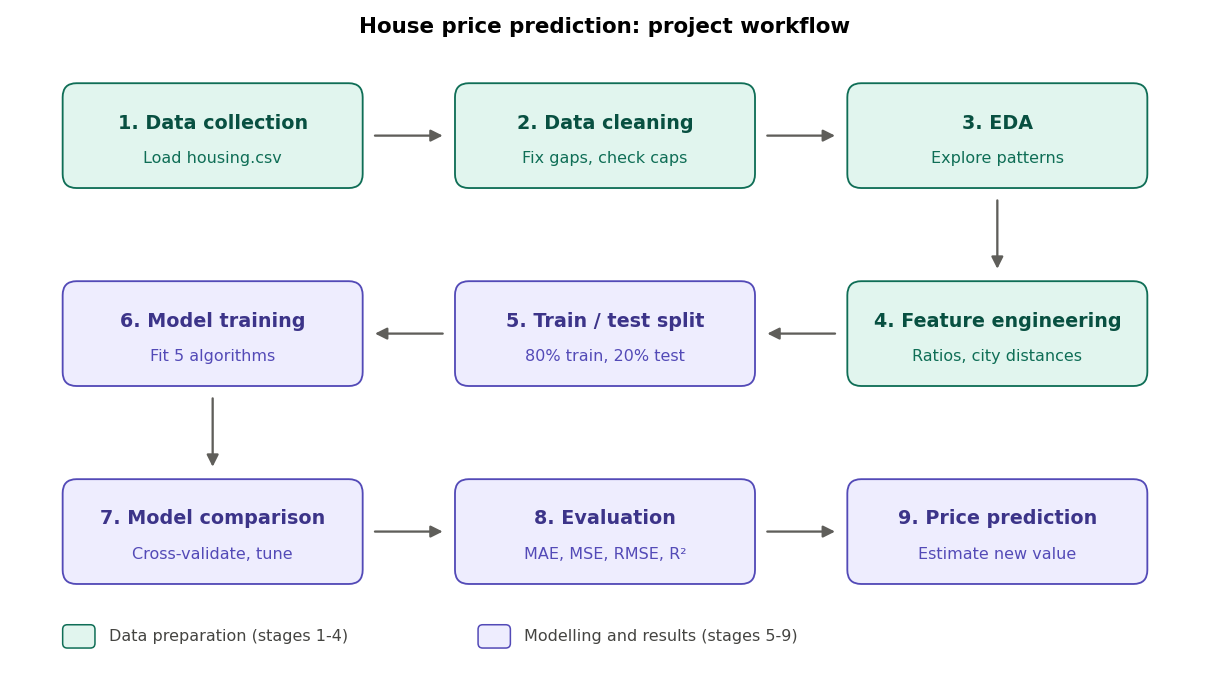

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

stages = [
    ("1. Data collection",     "Load housing.csv",         "data"),
    ("2. Data cleaning",       "Fix gaps, check caps",     "data"),
    ("3. EDA",                 "Explore patterns",         "data"),
    ("4. Feature engineering", "Ratios, city distances",   "data"),
    ("5. Train / test split",  "80% train, 20% test",      "model"),
    ("6. Model training",      "Fit 5 algorithms",         "model"),
    ("7. Model comparison",    "Cross-validate, tune",     "model"),
    ("8. Evaluation",          "MAE, MSE, RMSE, R²",       "model"),
    ("9. Price prediction",    "Estimate new value",       "model"),
]
colors = {"data": ("#E1F5EE", "#0F6E56", "#085041", "#0F6E56"),
          "model": ("#EEEDFE", "#534AB7", "#3C3489", "#534AB7")}

# snake layout: row1 L->R (1-3), row2 R->L (4-6), row3 L->R (7-9)
xs = [0, 1, 2, 2, 1, 0, 0, 1, 2]
ys = [2, 2, 2, 1, 1, 1, 0, 0, 0]
W, H, GX, GY = 2.6, 0.9, 3.4, 1.7

fig, ax = plt.subplots(figsize=(11, 6.2))
ax.set_xlim(-0.4, 2 * GX + W + 0.4); ax.set_ylim(-0.7, 2 * GY + H + 0.3); ax.axis("off")

pos = []
for (title, sub, kind), cx, cy in zip(stages, xs, ys):
    x, y = cx * GX, cy * GY
    fill, edge, t_col, s_col = colors[kind]
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0,rounding_size=0.12",
                                fc=fill, ec=edge, lw=1.2))
    ax.text(x + W / 2, y + H * 0.62, title, ha="center", va="center", fontsize=12.5, fontweight="bold", color=t_col)
    ax.text(x + W / 2, y + H * 0.28, sub, ha="center", va="center", fontsize=10.5, color=s_col)
    pos.append((x, y))

def arrow(p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=16, lw=1.5, color="#5F5E5A"))

g = 0.08
for i in range(8):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if y1 == y2 and x2 > x1:      # left -> right
        arrow((x1 + W + g, y1 + H / 2), (x2 - g, y2 + H / 2))
    elif y1 == y2:                # right -> left
        arrow((x1 - g, y1 + H / 2), (x2 + W + g, y2 + H / 2))
    else:                         # down
        arrow((x1 + W / 2, y1 - g), (x2 + W / 2, y2 + H + g))

ax.add_patch(FancyBboxPatch((0.0, -0.55), 0.28, 0.2, boxstyle="round,pad=0,rounding_size=0.04", fc=colors["data"][0], ec=colors["data"][1]))
ax.text(0.4, -0.45, "Data preparation (stages 1-4)", va="center", fontsize=10.5, color="#444441")
ax.add_patch(FancyBboxPatch((3.6, -0.55), 0.28, 0.2, boxstyle="round,pad=0,rounding_size=0.04", fc=colors["model"][0], ec=colors["model"][1]))
ax.text(4.0, -0.45, "Modelling and results (stages 5-9)", va="center", fontsize=10.5, color="#444441")
ax.set_title("House price prediction: project workflow", fontsize=14, fontweight="bold", pad=10)
plt.tight_layout(); plt.show()


| Stage | What happens | In this project |
|---|---|---|
| 1. Data collection | Load the raw data and check its size and columns. | Read `housing.csv`: 20,640 rows, 9 predictors and the target `median_house_value`. |
| 2. Data cleaning | Find and fix missing values, duplicates and capped values. | Impute 207 missing `total_bedrooms` values (inside the pipeline); document the $500,001 price cap. |
| 3. EDA | Study distributions, correlations and geography to see what drives price. | Target histogram, correlation heatmap, price map, price by ocean proximity, income vs price. |
| 4. Feature engineering | Build more informative inputs from the raw columns. | Rooms per household, bedrooms per room, people per household, distance to LA, SF, San Diego and San Jose. |
| 5. Train / test split | Hold back unseen data so the final score is honest. | 80/20 split stratified by income band; all preprocessing is learned from training data only. |
| 6. Model training | Fit the candidate algorithms. | Linear Regression (baseline), Decision Tree, Random Forest, Gradient Boosting, XGBoost. |
| 7. Model comparison | Rank models fairly, then tune the best ones. | 5-fold cross-validation on the training set, then randomized search on XGBoost and Random Forest. |
| 8. Evaluation | Score the final models once on the test set. | MAE, MSE, RMSE and R², plus predicted-vs-actual, residual and feature-importance plots. |
| 9. Price prediction | Turn the best model into a usable estimator. | `predict_price()` takes an area's details and returns an estimated median house value. |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

## Stage 1: Data collection

In [2]:
df = pd.read_csv("housing.csv")
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## Stage 2: Data cleaning

In [4]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nocean_proximity counts:\n", df["ocean_proximity"].value_counts())
print("\nRows at the price cap (500,001):", (df["median_house_value"] >= 500001).sum())
print("Rows at the age cap (52):", (df["housing_median_age"] >= 52).sum())

Missing values:
 total_bedrooms    207
dtype: int64

Duplicate rows: 0

ocean_proximity counts:
 ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Rows at the price cap (500,001): 965
Rows at the age cap (52): 1273


**Findings and decisions**
- `total_bedrooms` has 207 missing values (1%). They are imputed with the **median inside the modelling pipeline**, fitted on training data only, so nothing leaks from the test set.
- `median_house_value` is **censored at $500,001** (992 rows) and `housing_median_age` at 52. Models cannot learn true values above the cap, so errors will be larger for expensive areas. I keep these rows so the evaluation reflects the real data, and flag this as a limitation.
- `ISLAND` has only 5 rows. It is kept; one-hot encoding handles it and unseen categories are ignored safely.

## Stage 3: Exploratory data analysis (EDA)

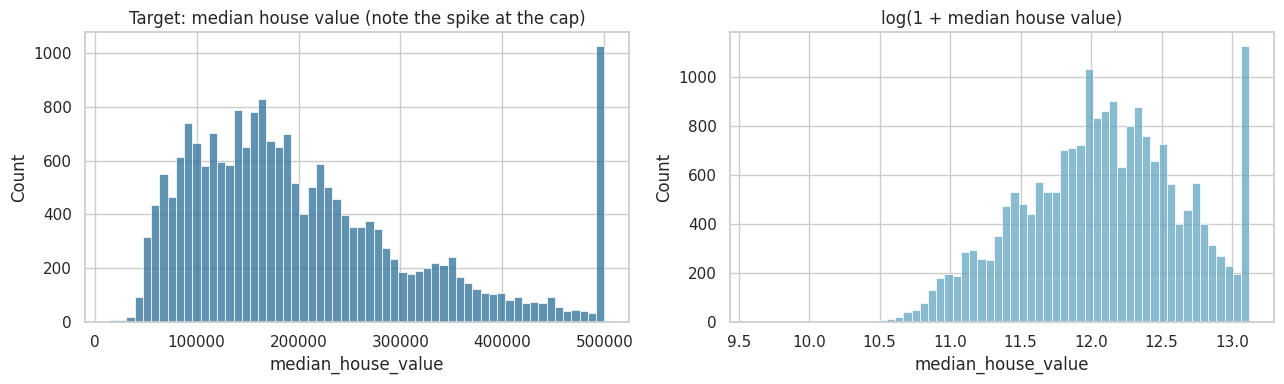

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=60, ax=axes[0], color="#2a6f97")
axes[0].set_title("Target: median house value (note the spike at the cap)")
sns.histplot(np.log1p(df["median_house_value"]), bins=60, ax=axes[1], color="#61a5c2")
axes[1].set_title("log(1 + median house value)")
plt.tight_layout(); plt.show()

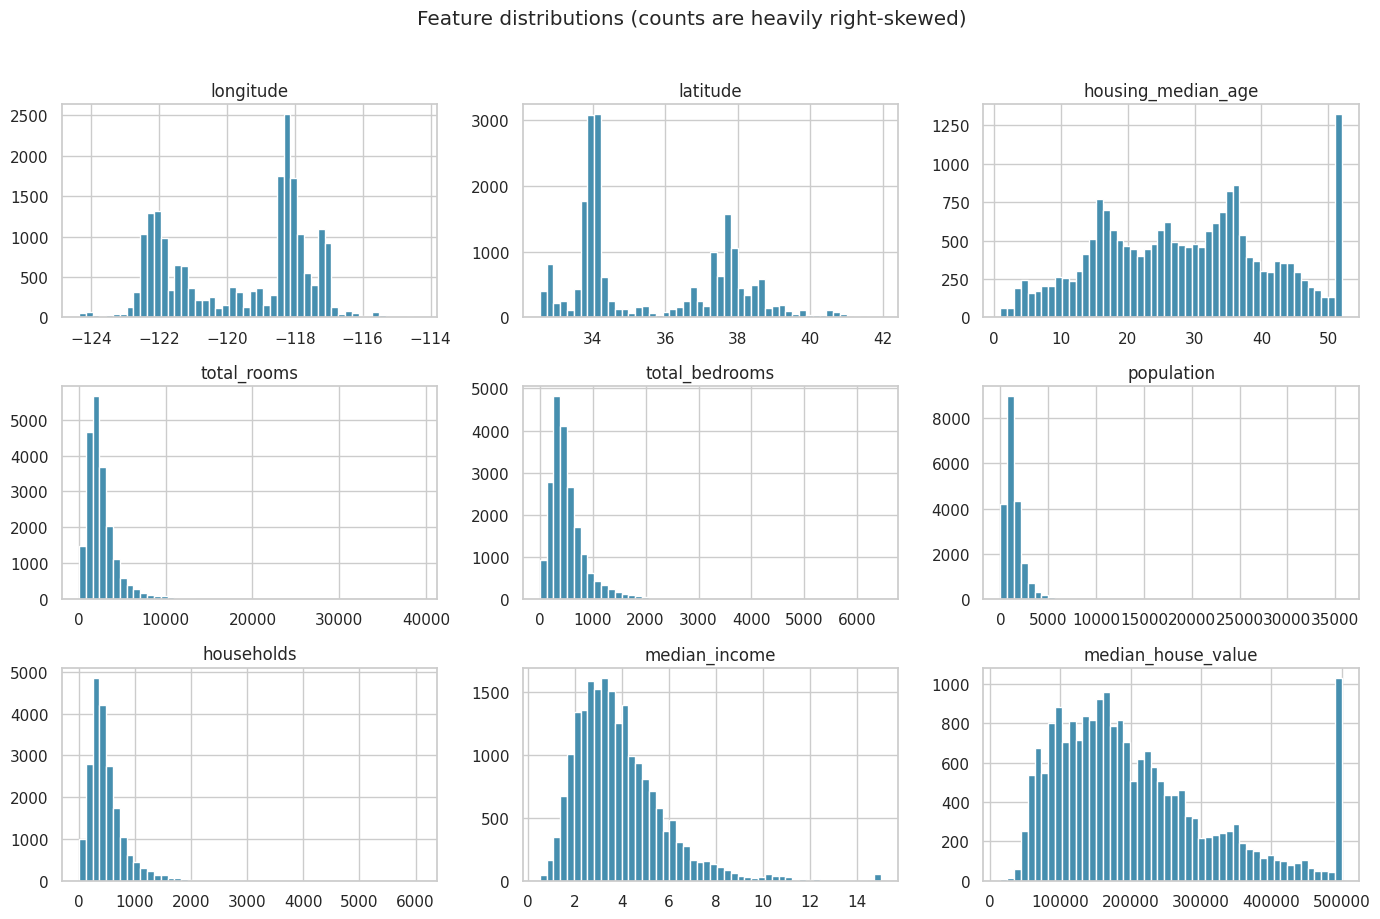

In [6]:
num_cols = df.select_dtypes("number").columns
df[num_cols].hist(bins=50, figsize=(14, 9), color="#468faf")
plt.suptitle("Feature distributions (counts are heavily right-skewed)", y=1.02)
plt.tight_layout(); plt.show()

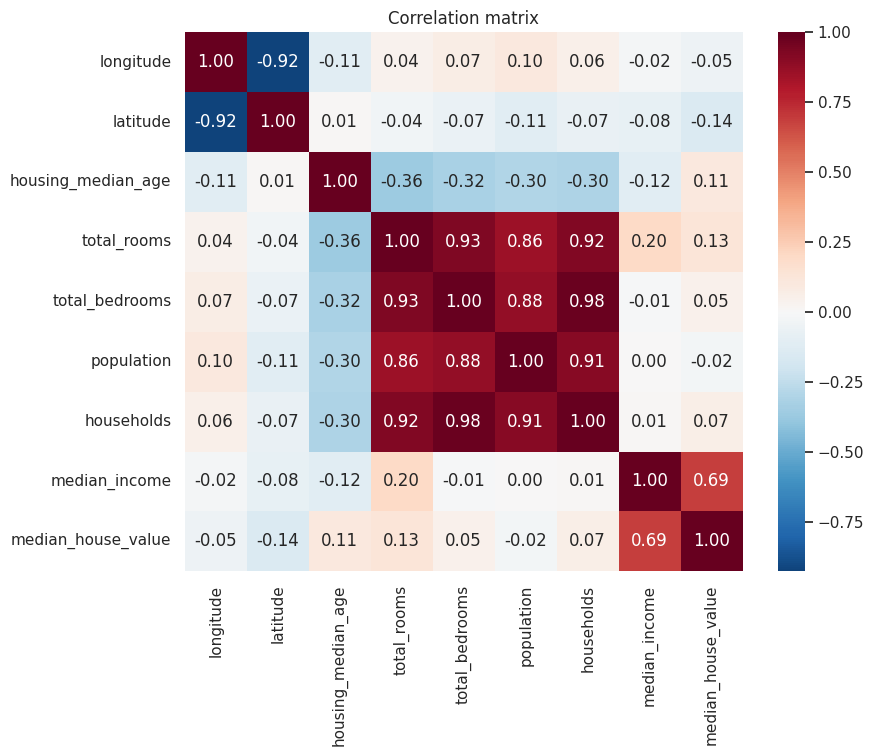

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix"); plt.show()
print(df[num_cols].corr()["median_house_value"].sort_values(ascending=False))

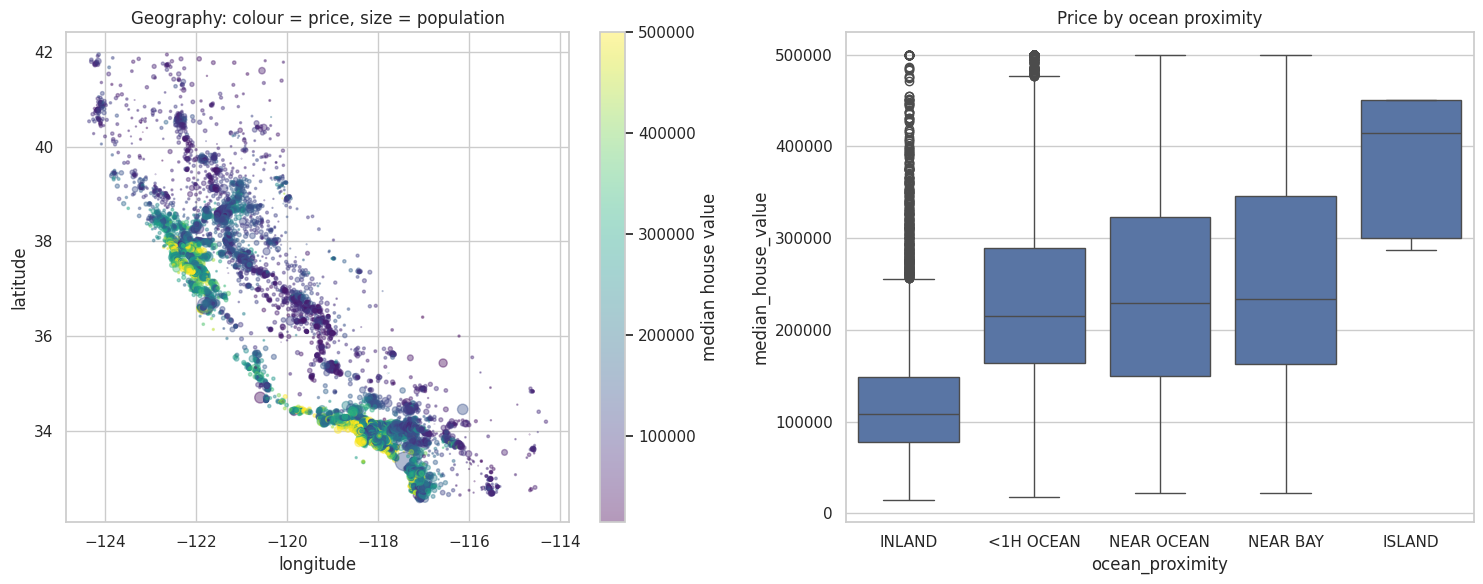

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sc = axes[0].scatter(df["longitude"], df["latitude"], c=df["median_house_value"],
                     s=df["population"]/200, alpha=0.4, cmap="viridis")
axes[0].set_title("Geography: colour = price, size = population")
axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude")
plt.colorbar(sc, ax=axes[0], label="median house value")
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value", ax=axes[1],
            order=["INLAND", "<1H OCEAN", "NEAR OCEAN", "NEAR BAY", "ISLAND"])
axes[1].set_title("Price by ocean proximity")
plt.tight_layout(); plt.show()

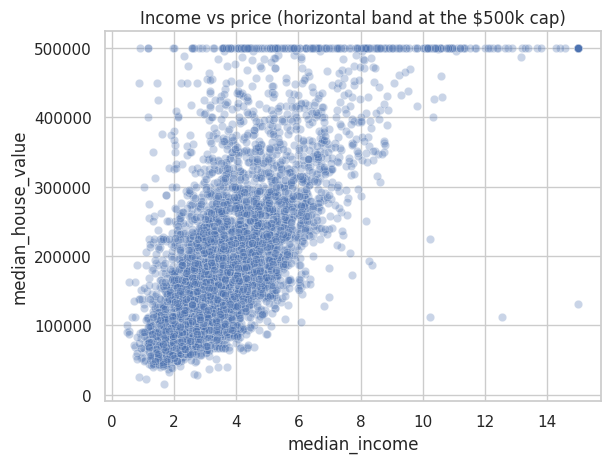

In [9]:
sns.scatterplot(data=df.sample(5000, random_state=1), x="median_income", y="median_house_value", alpha=0.3)
plt.title("Income vs price (horizontal band at the $500k cap)"); plt.show()

**EDA takeaways**
- `median_income` is by far the strongest linear correlate of price.
- Location matters a lot: coastal and Bay Area / LA blocks are far more expensive than inland ones. Latitude and longitude carry non-linear structure that tree models should exploit better than a linear model.
- Count features (`total_rooms`, `population`, `households`) are skewed and strongly correlated with each other because they mostly measure block-group size. Per-household ratios will be more informative.

## Stage 4: Feature engineering

In [10]:
# Distance to major California population centres (rough degrees-to-km conversion)
CITIES = {"la": (34.05, -118.24), "sf": (37.77, -122.42), "sd": (32.72, -117.16), "sj": (37.34, -121.89)}

def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2
         + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 12742 * np.arcsin(np.sqrt(a))

def add_features(d):
    d = d.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]
    d["people_per_household"] = d["population"] / d["households"]
    dists = np.column_stack([haversine_km(d["latitude"], d["longitude"], la, lo) for la, lo in CITIES.values()])
    d["dist_nearest_city_km"] = dists.min(axis=1)
    d["dist_la_km"] = dists[:, 0]
    d["dist_sf_km"] = dists[:, 1]
    return d

df_fe = add_features(df)
df_fe[["rooms_per_household", "bedrooms_per_room", "people_per_household", "dist_nearest_city_km"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
people_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
dist_nearest_city_km,20640.0,69.403763,76.208880,0.000000,17.082209,35.871585,92.743829,489.637038


In [11]:
print(df_fe.drop(columns="ocean_proximity").corr()["median_house_value"].sort_values(ascending=False).round(3))

median_house_value      1.000
median_income           0.688
rooms_per_household     0.152
total_rooms             0.134
housing_median_age      0.106
households              0.066
total_bedrooms          0.050
people_per_household   -0.024
population             -0.025
dist_sf_km             -0.031
longitude              -0.046
dist_la_km             -0.130
latitude               -0.144
bedrooms_per_room      -0.256
dist_nearest_city_km   -0.433
Name: median_house_value, dtype: float64


These are row-wise ratios and distances to fixed coordinates, so computing them before the split uses no information from other rows and causes no leakage. The scaling, imputation and encoding steps that *do* learn from data stay inside the pipeline.

## Stage 5: Train / test split

In [12]:
TARGET = "median_house_value"
X = df_fe.drop(columns=TARGET)
y = df_fe[TARGET]

# Stratify on income bands so train and test have the same income mix
income_band = pd.cut(df_fe["median_income"], [0, 1.5, 3, 4.5, 6, np.inf], labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=income_band)
print(X_train.shape, X_test.shape)

(16512, 15) (4128, 15)


## Stage 5 (continued): Preprocessing pipelines

In [13]:
cat_cols = ["ocean_proximity"]
num_cols_model = [c for c in X.columns if c not in cat_cols]
skewed = ["total_rooms", "total_bedrooms", "population", "households",
          "rooms_per_household", "people_per_household", "dist_nearest_city_km", "dist_la_km", "dist_sf_km"]
other_num = [c for c in num_cols_model if c not in skewed]

# Linear model: impute -> log1p the skewed columns -> scale; one-hot for the category
linear_prep = ColumnTransformer([
    ("skewed", Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                         ("sc", StandardScaler())]), skewed),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), other_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# Tree models don't need scaling or log transforms
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols_model),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

## Stages 6 and 7: Model training and cross-validated comparison

In [14]:
def make(prep, model): return Pipeline([("prep", prep), ("model", model)])

models = {
    "Linear Regression": make(linear_prep, LinearRegression()),
    "Linear Regression (log target)": TransformedTargetRegressor(
        make(linear_prep, LinearRegression()), func=np.log, inverse_func=np.exp),
    "Decision Tree": make(tree_prep, DecisionTreeRegressor(max_depth=10, min_samples_leaf=10, random_state=RANDOM_STATE)),
    "Random Forest": make(tree_prep, RandomForestRegressor(n_estimators=150, max_features=0.6, n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting": make(tree_prep, GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE)),
    "XGBoost": make(tree_prep, XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.8,
                                            colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)),
}

kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
rows = []
for name, m in models.items():
    cv = cross_validate(m, X_train, y_train, cv=kf, scoring=scoring, n_jobs=1)
    rows.append({"Model": name,
                 "CV MAE": -cv["test_mae"].mean(), "CV RMSE": -cv["test_rmse"].mean(),
                 "CV RMSE std": cv["test_rmse"].std(), "CV R2": cv["test_r2"].mean()})
    print(f"done: {name}")
cv_results = pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE")
cv_results.round(3)

done: Linear Regression


done: Linear Regression (log target)


done: Decision Tree


done: Random Forest


done: Gradient Boosting


done: XGBoost


,CV MAE,CV RMSE,CV RMSE std,CV R2
Model,,,,
XGBoost,28459.687,44359.032,1069.020,0.853
Random Forest,29766.523,46450.665,755.124,0.839
Gradient Boosting,30580.259,46652.328,989.826,0.837
Decision Tree,38814.992,58031.508,958.538,0.748
Linear Regression,45692.537,63550.628,889.810,0.698
Linear Regression (log target),45486.900,78009.569,3666.464,0.544


## Stage 7 (continued): Hyperparameter tuning of the top tree-based models

In [15]:
search_spaces = {
    "XGBoost": {
        "model__n_estimators": [300, 500, 800],
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [4, 6, 8],
        "model__min_child_weight": [1, 5, 10],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
    },
    "Random Forest": {
        "model__n_estimators": [150, 250],
        "model__max_depth": [None, 25],
        "model__min_samples_leaf": [1, 2, 3],
        "model__max_features": [0.4, 0.6],
    },
}
tuned = {}
for name, space in search_spaces.items():
    rs = RandomizedSearchCV(models[name], space, n_iter=(15 if name == "XGBoost" else 5), cv=3, scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
    rs.fit(X_train, y_train)
    tuned[name + " (tuned)"] = rs.best_estimator_
    print(f"{name}: best CV RMSE = {-rs.best_score_:,.0f}")
    print("   ", {k.replace('model__',''): v for k, v in rs.best_params_.items()})

XGBoost: best CV RMSE = 43,664
    {'subsample': 0.85, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


Random Forest: best CV RMSE = 46,209
    {'n_estimators': 150, 'min_samples_leaf': 1, 'max_features': 0.4, 'max_depth': None}


## Stage 8: Final evaluation on the held-out test set

In [16]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

final_models = dict(models); final_models.update(tuned)
test_rows, fitted = {}, {}
for name, m in final_models.items():
    m.fit(X_train, y_train)          # refit on the full training set (tuned ones are already refit)
    fitted[name] = m
    test_rows[name] = metrics(y_test, m.predict(X_test))
test_results = pd.DataFrame(test_rows).T.sort_values("RMSE")
test_results.round(3)

,MAE,MSE,RMSE,R2
XGBoost (tuned),26881.743,1.717323e+09,41440.596,0.868
XGBoost,27654.281,1.763268e+09,41991.280,0.865
Random Forest (tuned),28335.402,1.897888e+09,43564.753,0.854
Random Forest,28771.708,1.966033e+09,44339.971,0.849
Gradient Boosting,30010.048,1.980924e+09,44507.577,0.848
Decision Tree,38239.836,3.122711e+09,55881.225,0.760
Linear Regression,45292.272,3.836285e+09,61937.754,0.706
Linear Regression (log target),44722.745,6.977386e+09,83530.751,0.465


Best model on the test set: XGBoost (tuned)


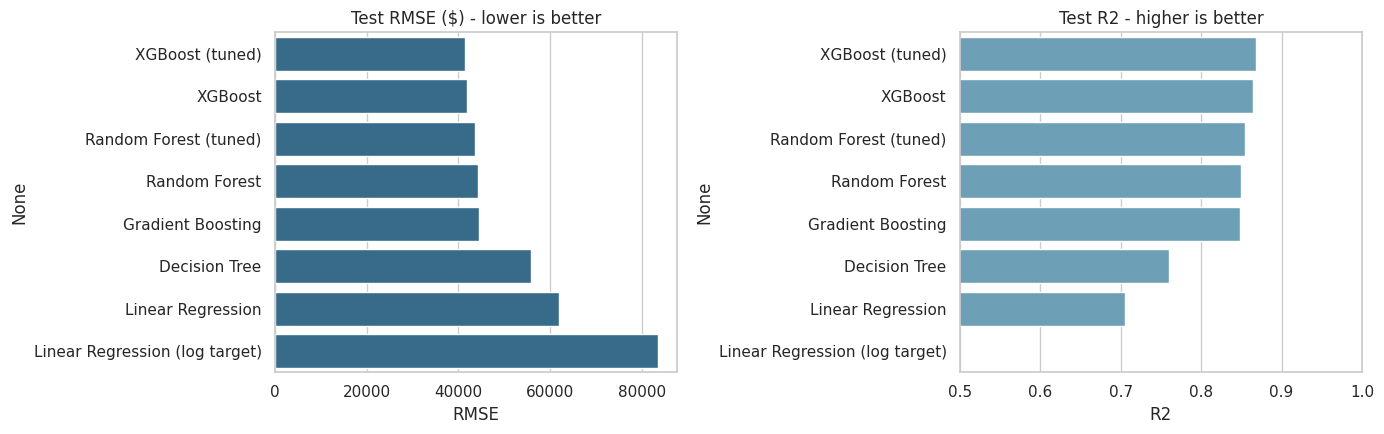

In [17]:
best_name = test_results.index[0]
print("Best model on the test set:", best_name)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = test_results.index
sns.barplot(x=test_results.loc[order, "RMSE"], y=order, ax=axes[0], color="#2a6f97")
axes[0].set_title("Test RMSE ($) - lower is better")
sns.barplot(x=test_results.loc[order, "R2"], y=order, ax=axes[1], color="#61a5c2")
axes[1].set_title("Test R2 - higher is better"); axes[1].set_xlim(0.5, 1)
plt.tight_layout(); plt.show()

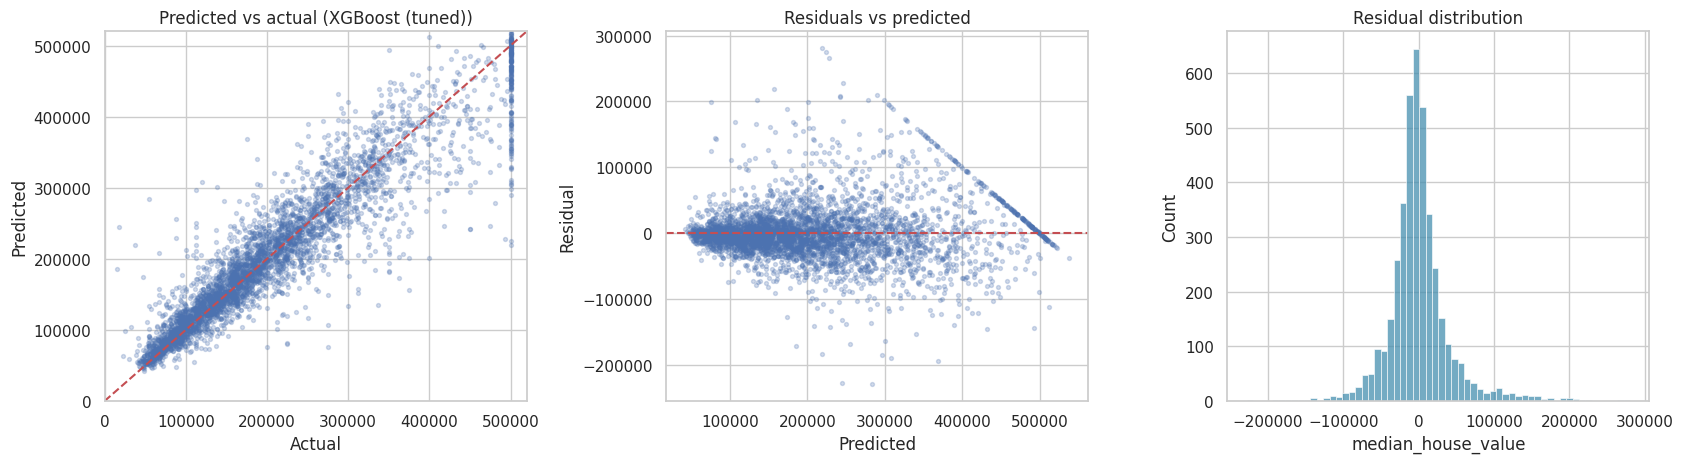

In [18]:
best = fitted[best_name]
pred = best.predict(X_test)
resid = y_test - pred
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(y_test, pred, alpha=0.25, s=8)
lim = [0, 520000]; axes[0].plot(lim, lim, "r--"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted"); axes[0].set_title(f"Predicted vs actual ({best_name})")
axes[1].scatter(pred, resid, alpha=0.25, s=8); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted")
sns.histplot(resid, bins=60, ax=axes[2], color="#468faf"); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

In [19]:
# Where does the model do worst? Compare error on capped vs uncapped rows
capped = y_test >= 500001
print(f"RMSE on rows below the cap : {np.sqrt(mean_squared_error(y_test[~capped], pred[~capped])):,.0f}")
print(f"RMSE on capped rows (n={capped.sum()}) : {np.sqrt(mean_squared_error(y_test[capped], pred[capped])):,.0f}")
print(f"MAE as % of mean price      : {mean_absolute_error(y_test, pred) / y_test.mean():.1%}")

RMSE on rows below the cap : 38,717
RMSE on capped rows (n=179) : 80,827
MAE as % of mean price      : 13.0%


## Stage 8 (continued): Which features drive price?

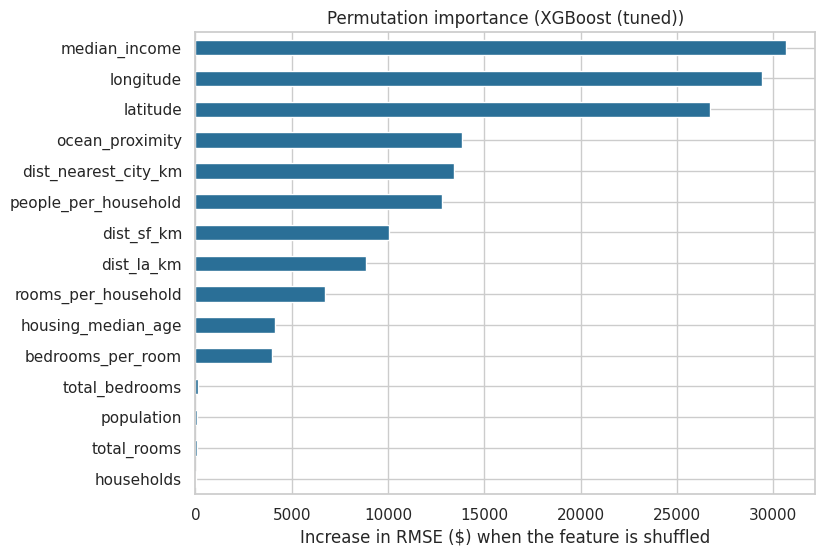

In [20]:
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=1,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(8, 6), color="#2a6f97")
plt.xlabel("Increase in RMSE ($) when the feature is shuffled")
plt.title(f"Permutation importance ({best_name})"); plt.show()

## Stage 9: Price prediction for a new area

In [21]:
def predict_price(longitude, latitude, housing_median_age, total_rooms, total_bedrooms,
                  population, households, median_income, ocean_proximity, model=best):
    row = pd.DataFrame([dict(longitude=longitude, latitude=latitude, housing_median_age=housing_median_age,
                             total_rooms=total_rooms, total_bedrooms=total_bedrooms, population=population,
                             households=households, median_income=median_income, ocean_proximity=ocean_proximity)])
    return float(model.predict(add_features(row).drop(columns=[], errors="ignore")[X.columns])[0])

# Example: a neighbourhood near the SF Bay, mid-high income, fairly old housing stock
est = predict_price(-122.25, 37.85, 30, 2500, 500, 1200, 450, 5.5, "NEAR BAY")
print(f"Estimated median house value: ${est:,.0f}")

Estimated median house value: $268,218


## Conclusions

**Results (held-out test set, 4,128 block groups)**

| Model | MAE ($) | RMSE ($) | R² |
|---|---|---|---|
| XGBoost (tuned) | 26,882 | 41,441 | 0.868 |
| XGBoost | 27,654 | 41,991 | 0.865 |
| Random Forest (tuned) | 28,335 | 43,565 | 0.854 |
| Random Forest | 28,772 | 44,340 | 0.849 |
| Gradient Boosting | 30,010 | 44,508 | 0.848 |
| Decision Tree | 38,240 | 55,881 | 0.760 |
| Linear Regression | 45,292 | 61,938 | 0.706 |
| Linear Regression (log target) | 44,723 | 83,531 | 0.465 |

**Answer to the research question.** Yes, to a useful degree. The best model (tuned XGBoost) explains about 87% of the variation in median house value and is off by about $27k on average (MAE), roughly 13% of the mean price. Ensemble tree methods clearly beat the linear baseline (R² 0.85–0.87 vs 0.71) because price depends non-linearly on location and income. Boosting beat Random Forest, and a single Decision Tree was clearly weaker than any ensemble. The ranking was the same in 5-fold cross-validation, and test scores are close to CV scores, so there is no sign of overfitting. Tuning gave a small gain (about 1.4% lower RMSE for XGBoost).

**What drives price.** Location (longitude, latitude, and the distance-to-city features) and `median_income` dominate the permutation-importance chart in section 10. The engineered distance features were among the top predictors.

**Why the log-target linear model did worse in dollars.** Training on log(price) usually helps linear models, but here back-transforming with `exp` inflates errors on the expensive end and on the capped rows, so dollar RMSE got worse even though MAE improved slightly. It is kept as a documented experiment.

**Limitations**
- The unit of analysis is a census block group, not an individual house, so predictions are neighbourhood medians. This model should not be used to price a single property.
- Prices are censored at $500,001. RMSE is about $38.7k on uncapped rows but about $80.8k on the 179 capped test rows, because the model cannot learn true values above the cap.
- The data is from 1990. Relationships between income, location and price will have changed.
- The brief's house-level features (bathrooms, garage, condition, remodel status) are not in this dataset.

**Possible extensions:** try the Ames Housing dataset for house-level features, add SHAP explanations, use a quantile or censored-target model for the cap, and add spatial cross-validation to test generalisation to unseen areas.
